In [2]:
# standard libraries
import os, sys, json, time, glob
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output
from skimage.metrics import peak_signal_noise_ratio as psnr
from datetime import datetime
import copy
import json

# your project modules (run from the ambient_flow_MRI folder)
sys.path.append(os.getcwd())
from model.model import build_unet, UNetVelocity
from loss.loss import ambient_loss
from data.data import BrainAmbientFlowMatchingDataset
from util.helper import *

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [3]:
model = build_unet().to(device)                       # same constructor as in training
ckpt = torch.load("run/20261108_135641/best.pt", map_location=device)
model.load_state_dict(ckpt["model"] if "model" in ckpt else ckpt)
model.eval()
import inspect, flow_matching.utils as fu
print(inspect.getsource(fu.ModelWrapper.__init__))

    def __init__(self, model: nn.Module):
        super().__init__()
        self.model = model



/tmp/ipykernel_3661920/1497534253.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load("run/20261108_135641/best.pt", map_location=device)


In [4]:
split_index = json.load(open("/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/split_16x320x320.json"))
set = BrainAmbientFlowMatchingDataset(index=split_index["train"], accel=4, cf=0.08)
dataloader = torch.utils.data.DataLoader(set, batch_size=1, shuffle=True)
y, A, _ = next(iter(dataloader))
y = y.to(device)
A = A.to(device)
print(y.shape, A.shape)

torch.Size([1, 16, 320, 320]) torch.Size([1, 1, 1, 320])


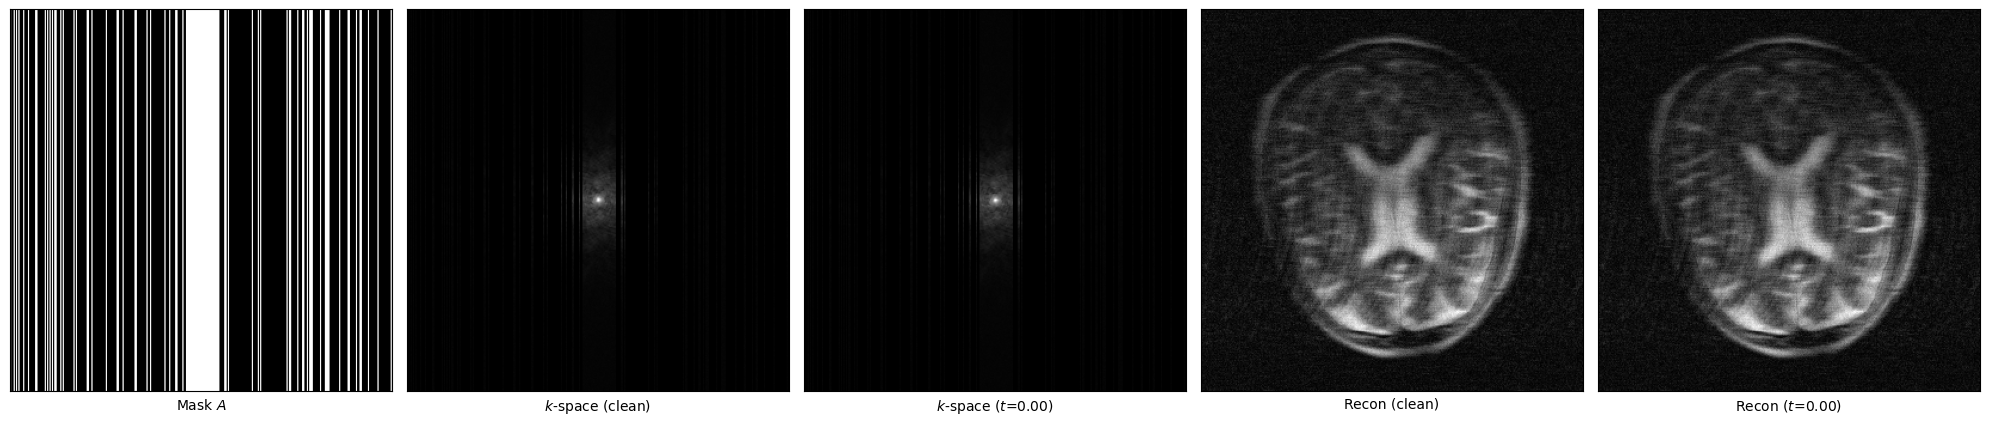

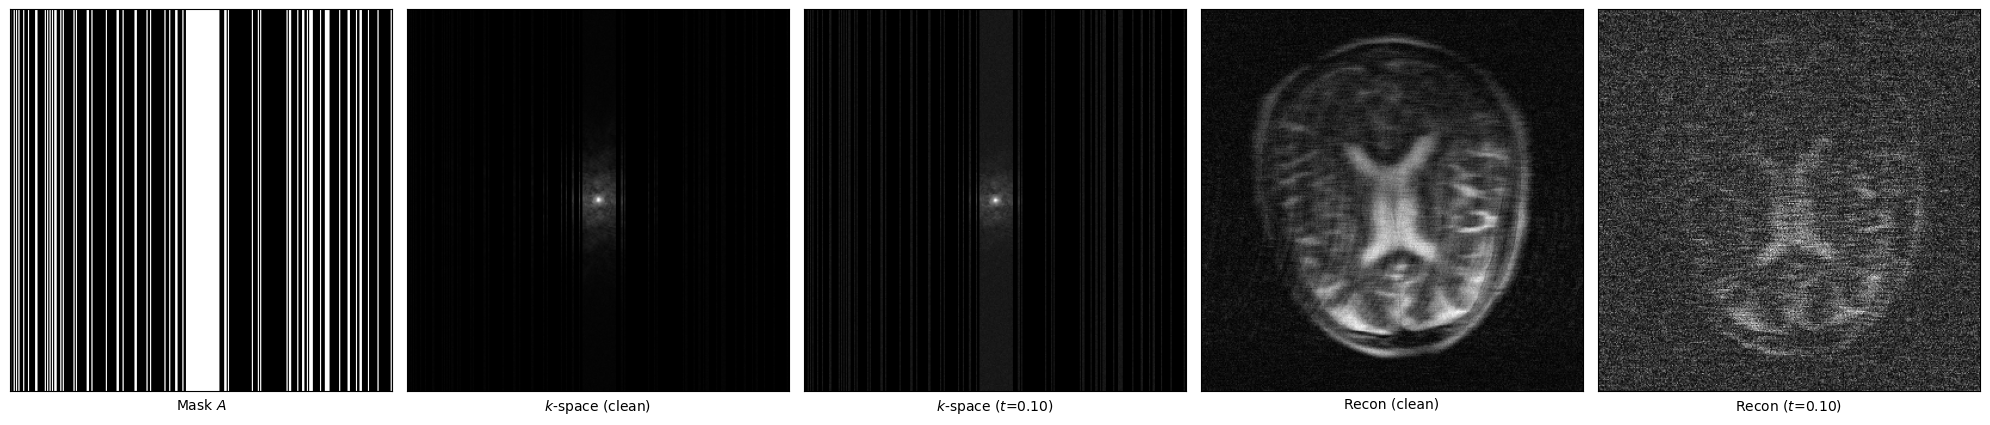

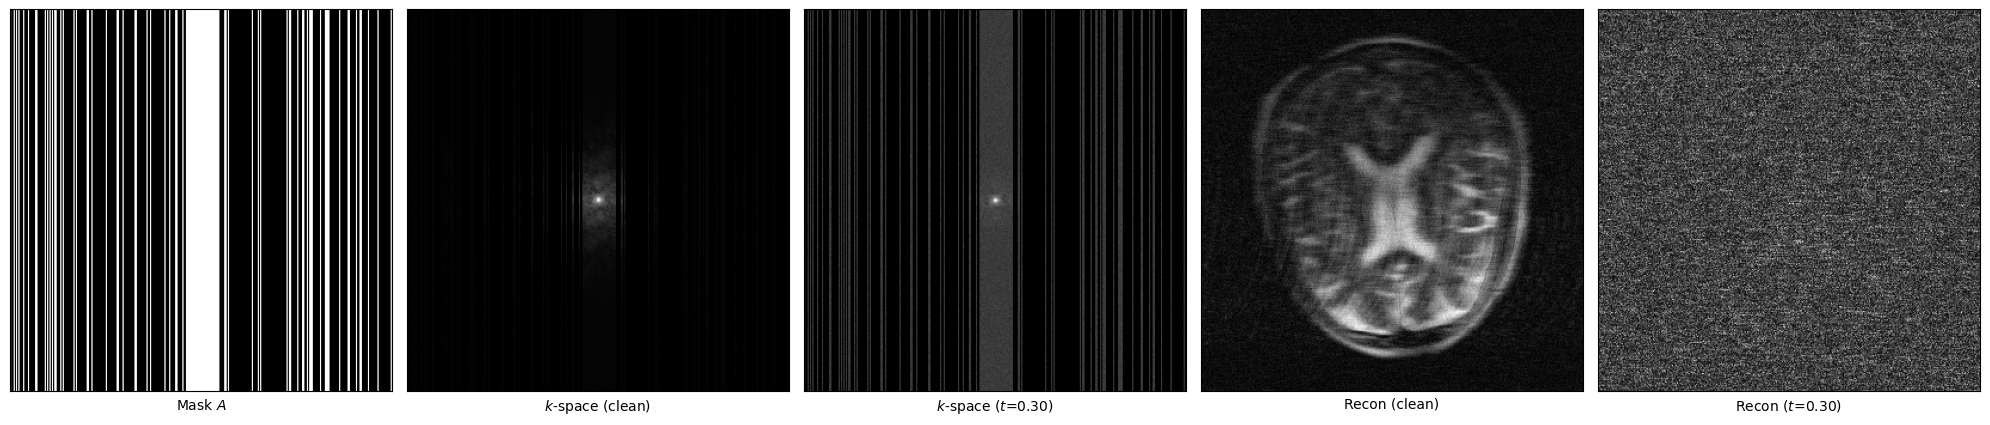

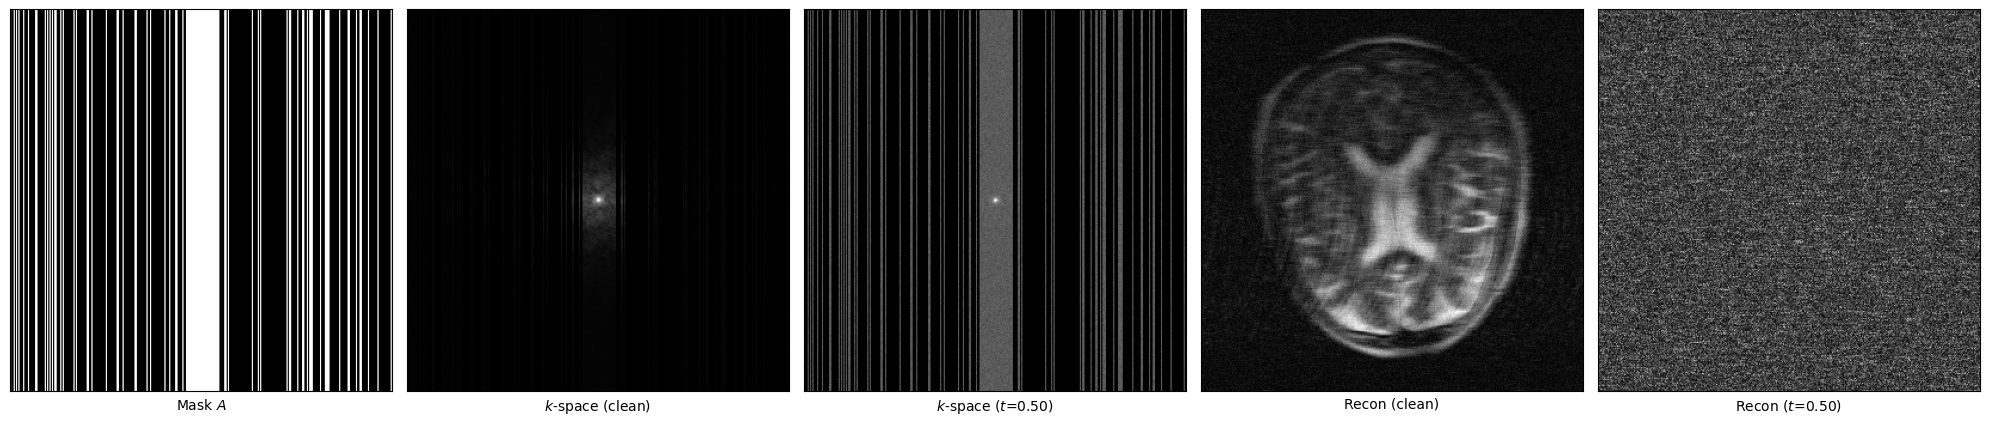

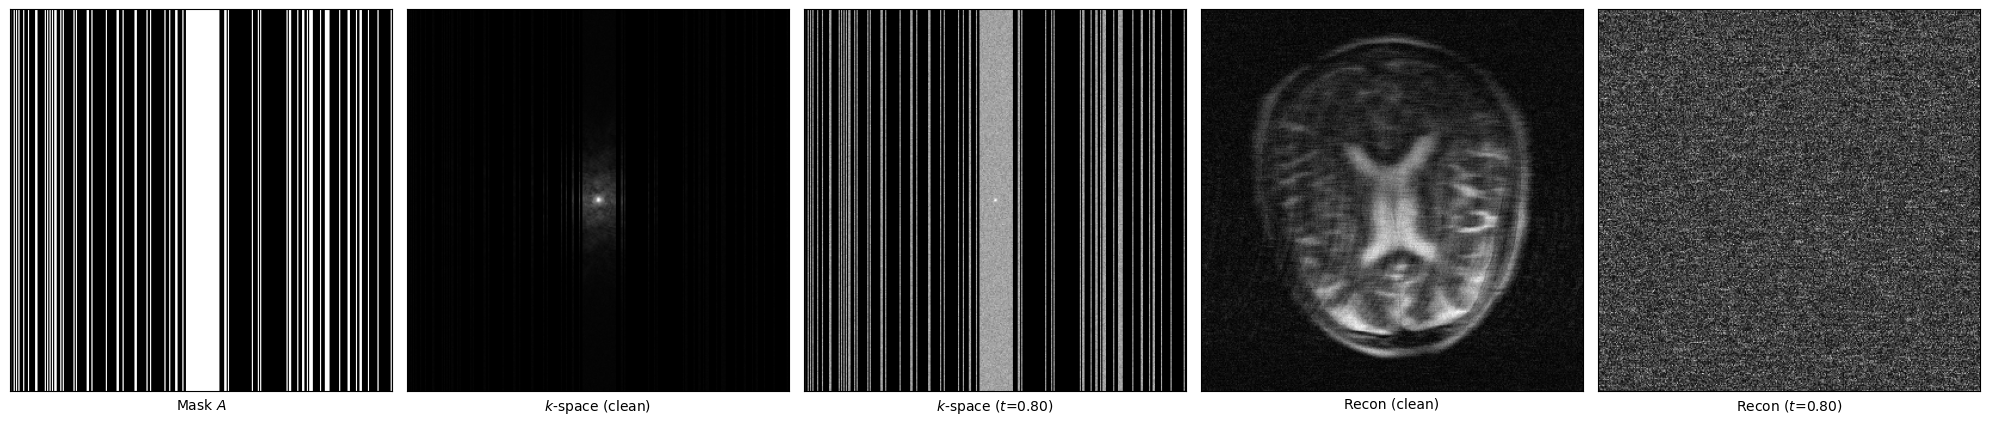

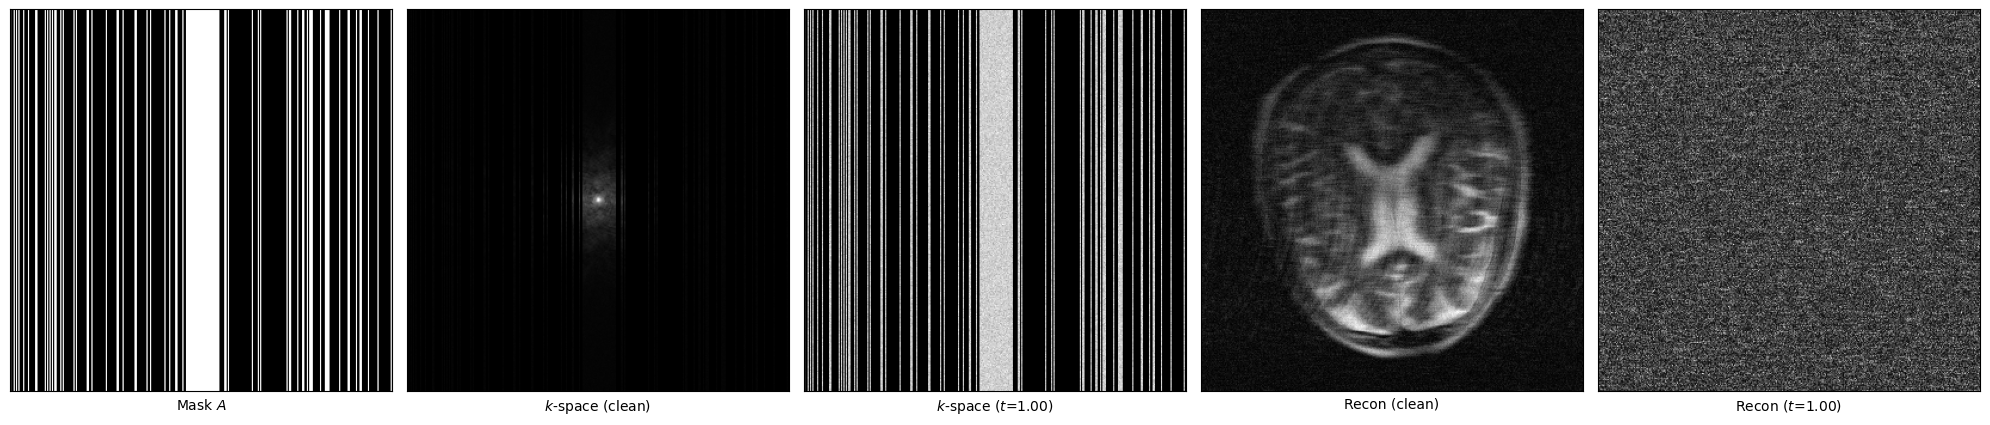

In [5]:
from util.helper import rss, ifft2c
for t in [0.0, 0.1, 0.3, 0.5, 0.8, 1.0]:
    plot_image(y, A, t=t)

unet = build_unet().to(device)
unet.load_state_dict(torch.load("/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/run/20261108_012735/best.pt", map_location=device))
unet.eval()

In [6]:
ckpt = torch.load("/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/run/20261108_135641/best.pt",
                  map_location=device)
print("best_val:", ckpt["best_val"])
unet = build_unet().to(device)
unet.load_state_dict(ckpt["model"])
unet.eval()
mask = A.expand(1, 1, 320, 320).float().to(device)
vel = UNetVelocity(unet, mask)

/tmp/ipykernel_3661920/3201050758.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load("/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/run/20261108_13

best_val: 0.013510776683688164


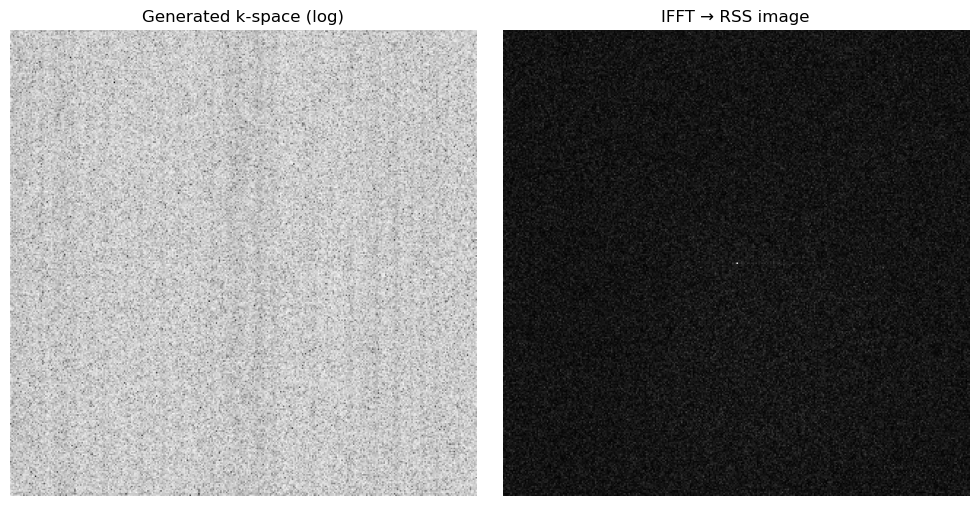

In [ ]:
@torch.no_grad()
def solve(n_steps=50, noise_at_t1=False, seed=0):
    torch.manual_seed(seed)
    x = torch.randn(1, 32, 320, 320, device=device)            # 1. Gaussian noise
    ts = torch.linspace(1, 0, n_steps + 1) if noise_at_t1 else torch.linspace(0, 1, n_steps + 1)
    for t0, t1 in zip(ts[:-1], ts[1:]):
        h = (t1 - t0).item()                                   # negative when going 1 -> 0
        v = vel(x, torch.tensor([t0.item()], device=device))  # 2. predict velocity
        x = x + h * v                                          # 3. step (h<0 gives x - |h| v)
    return x                                                   # 4. repeated -> brain image

xx_k = solve(n_steps=500, noise_at_t1=False)       # (1, 32, 320, 320) k-space
k_c = torch.complex(x_k[:, :16], x_k[:, 16:])    # (1, 16, 320, 320) complex coils

k_mag = rss(k_c)[0].cpu()                        # coil-combined k-space magnitude
img   = rss(ifft2c(k_c))[0].cpu()                # IFFT each coil, then RSS

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(torch.log(k_mag + 1e-6), cmap="gray"); ax[0].set_title("Generated k-space (log)")
ax[1].imshow(img, cmap="gray");                     ax[1].set_title("IFFT → RSS image")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()